<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/Arquitetura_MLP_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.random.set_seed(42); np.random.seed(42)


In [4]:
URL = ("https://raw.githubusercontent.com/djeada/"
       "kaggle-house-prices/master/data/train.csv")
df = pd.read_csv(URL)
print(df.shape)

(1460, 81)


In [6]:
y = np.log1p(df["SalePrice"])          # log do preço: distribui melhor e estabiliza o treino
X = df.drop(columns=["Id", "SalePrice"])

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

X[num_cols] = X[num_cols].fillna(X[num_cols].median())   # faltantes numéricos → mediana
X[cat_cols] = X[cat_cols].fillna("Sem")                  # ex.: PoolQC vazio → "Sem piscina"

X = pd.get_dummies(X, columns=cat_cols, dtype=float)     # one-hot → ~300 colunas
print("Entradas após one-hot:", X.shape[1])              # é este número que aparece no diagrama

Entradas após one-hot: 303


In [7]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_tr[num_cols])            # ajusta SÓ no treino (evita vazamento)
X_tr[num_cols] = scaler.transform(X_tr[num_cols])
X_va[num_cols] = scaler.transform(X_va[num_cols])

X_tr = X_tr.values.astype("float32"); X_va = X_va.values.astype("float32")
y_tr = y_tr.values.astype("float32"); y_va = y_va.values.astype("float32")

In [8]:
n_in = X_tr.shape[1]
model = keras.Sequential([
    layers.Input(shape=(n_in,)),                 # 316 entradas padronizadas
    layers.Dense(128, activation="relu"),        # oculta 1 → (316+1)×128 = 40.576 parâmetros
    layers.Dense(64,  activation="relu"),        # oculta 2 → (128+1)×64  =  8.256
    layers.Dense(1,   activation="linear"),      # saída    → (64+1)×1    =     65   (preço em log)
])
model.summary()                                  # confira: Total params ≈ 48.897

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        38,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,233 (184.50 KB)

 Trainable params: 47,233 (184.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="mse",
              metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])

In [10]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                      restore_best_weights=True)
hist = model.fit(X_tr, y_tr,
                 validation_data=(X_va, y_va),
                 epochs=300, batch_size=32,
                 callbacks=[early], verbose=1)

Epoch 1/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 39.7328 - rmse: 6.3034 - val_loss: 0.4732 - val_rmse: 0.6879
Epoch 2/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6667 - rmse: 0.8165 - val_loss: 0.2245 - val_rmse: 0.4738
Epoch 3/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1813 - rmse: 0.4257 - val_loss: 0.1466 - val_rmse: 0.3829
Epoch 4/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1108 - rmse: 0.3328 - val_loss: 0.1079 - val_rmse: 0.3285
Epoch 5/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0783 - rmse: 0.2799 - val_loss: 0.0877 - val_rmse: 0.2962
Epoch 6/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0601 - rmse: 0.2452 - val_loss: 0.0750 - val_rmse: 0.2739
Epoch 7/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0481 - rmse: 0.2193 - val_loss: 0.0657 - val_rmse: 0.2563
Epoch 8/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0398 - rmse: 0.1994 - val_loss: 0.0589 - val_rmse: 0.2426
Epoch 9/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms

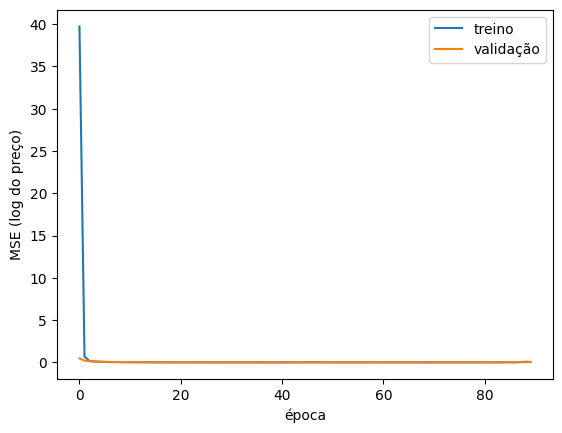

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
RMSE (log) = 0.1570   |   erro percentual médio = 11.4%


In [11]:
plt.plot(hist.history["loss"], label="treino")
plt.plot(hist.history["val_loss"], label="validação")
plt.xlabel("época"); plt.ylabel("MSE (log do preço)"); plt.legend(); plt.show()

# %% 9. Avaliar em dólares (desfazendo o log) ------------------------------
pred_log = model.predict(X_va).ravel()
pred_usd = np.expm1(pred_log); real_usd = np.expm1(y_va)
rmse_log = np.sqrt(np.mean((pred_log - y_va) ** 2))
mape = np.mean(np.abs(pred_usd - real_usd) / real_usd) * 100
print(f"RMSE (log) = {rmse_log:.4f}   |   erro percentual médio = {mape:.1f}%")

In [12]:
i = 0
print(f"Imóvel {i}: real US$ {real_usd[i]:,.0f}  →  previsto US$ {pred_usd[i]:,.0f}")

Imóvel 0: real US$ 154,500  →  previsto US$ 152,081


In [13]:
i = 0
print(f"Imóvel {i}: real US$ {real_usd[i]:,.0f}  →  previsto US$ {pred_usd[i]:,.0f}")

Imóvel 0: real US$ 154,500  →  previsto US$ 152,081
